# Visualization & Evaluation of models
## Installation

> pandas: Data manipulation <br>
> numpy: Data calculation <br>
> seaborn: Visualization <br>
> matplotlib.pyplot: Visualization <br>

> fitting: Limited-memory Broyden–Fletcher–Goldfarb–Shanno with Bounds (L-BFGS-B)


In [2]:
# from cmdstanpy import install_cmdstan

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom
from scipy.optimize import minimize

import os
import sys
from sklearn.metrics import mean_squared_error

# フォントキャッシュの更新
!fc-cache -f -v > /dev/null

# Matplotlib で Arial フォントを使用
from matplotlib import pyplot as plt
plt.rcParams['font.sans-serif'] = ['Noto Sans CJK JP', 'DejaVu Sans', 'sans-serif']

/bin/bash: line 1: fc-cache: command not found


In [3]:

print(sys.executable)
print(os.getcwd())
print(os.listdir("/workspace"))
# os.listdir()

/usr/local/bin/python
/workspace/scripts/visualization
['.DS_Store', 'requirements.txt', 'references', 'Dockerfile', 'docs', '.devcontainer', 'README.md', 'results', '.gitignore', 'scripts', '.gitattributes', '.git', 'data']


In [5]:
df = pd.read_csv(r"/workspace/results/dataframe/df_model_fit_results.csv", low_memory=False)
display(df)

,Bacterial_species,Additive_type,Stress_level,Additive_concentration,Elapsed_time_[days],model_type,RMSE,AIC,parameter_1,parameter_2,parameter_set
0,B.cereus,Glycine_[w/v_%],Low,1.4,3,exponential,0.065526,-45.029191,0.006151,NaN,[p]
1,B.cereus,Glycine_[w/v_%],High,1.6,3,exponential,0.049834,-54.884385,0.000056,NaN,[p]
2,B.cereus,Glycine_[w/v_%],Low,1.4,7,exponential,0.057032,-50.027200,0.060982,NaN,[p]
3,B.cereus,Glycine_[w/v_%],High,1.6,7,exponential,0.028204,-75.377332,0.000096,NaN,[p]
4,B.cereus,NaCl_[w/v_%],Low,7.0,3,exponential,0.118642,-23.657476,0.003054,NaN,[p]
...,...,...,...,...,...,...,...,...,...,...,...
59,E.coli,Glycine_[w/v_%],High,1.8,7,logistic,0.022837,-80.976139,-12.419759,1.121031,"[a0,a1]"
60,E.coli,NaCl_[w/v_%],Low,6.5,3,logistic,0.039620,-61.141116,-30.563736,4.614260,"[a0,a1]"
61,E.coli,NaCl_[w/v_%],High,7.0,3,logistic,0.039606,-61.153647,-21.223515,1.948863,"[a0,a1]"
62,E.coli,NaCl_[w/v_%],Low,6.5,7,logistic,0.089833,-31.671051,-1.640873,1.144313,"[a0,a1]"


In [163]:
# ----------------------------------------
# General plot function
# ----------------------------------------
def plot_metric_by_model(
    df: pd.DataFrame,
    bacterial_species: str,
    additive_type: str,
    elapsed_time_days: float,
    metric_col: str = "RMSE",
    save: bool = False,
    save_dir: str = "/workspace/results/figures",
    filename_base: str | None = None,
) -> None:
    """
    Create a *horizontal* bar plot of metric_col vs model_type.
    One figure per (Bacterial_species, Additive_type, Elapsed_time_[days]).
    Bars are grouped by model_type and colored/hatched by Additive_concentration.

    Parameters
    ----------
    save : bool
        If True, save the figure as TIFF files.
    save_dir : str
        Directory to save figures.
    filename_base : str | None
        Base name of the output file (without extension).
        If None, a name will be generated from the arguments.
    """

    if metric_col not in df.columns:
        raise ValueError(f"Column '{metric_col}' is not in the DataFrame.")

    # ----------------------------------------
    # Filter data
    # ----------------------------------------
    mask = (
        (df["Bacterial_species"] == bacterial_species)
        & (df["Additive_type"] == additive_type)
        & (df["Elapsed_time_[days]"] == elapsed_time_days)
    )
    sub = df.loc[mask].copy()

    if sub.empty:
        print("No data found for the specified conditions.")
        print(f"Bacterial_species: {bacterial_species}")
        print(f"Additive_type: {additive_type}")
        print(f"Elapsed_time_[days]: {elapsed_time_days}")
        return

    # ----------------------------------------
    # model_type order & label mapping
    # ----------------------------------------
    model_label_map = {
        "single_hit":   "Single-hit model",
        "exponential":  "Exponential model",
        "beta_poisson": "Beta-Poisson model",
        "logistic":     "Logistic regression model",
    }
    # desired order
    desired_order = ["beta_poisson", "exponential", "single_hit", "logistic"]

    # keep only model_types that actually exist in sub, preserving desired order
    model_types = [m for m in desired_order if m in sub["model_type"].unique()]

    if len(model_types) == 0:
        print("No valid model_type found for this subset.")
        return

    # y positions
    y = np.arange(len(model_types))
    conc_levels = np.sort(sub["Additive_concentration"].unique())
    n_conc = len(conc_levels)
    height = 0.8 / max(n_conc, 1)

    # ----------------------------------------
    # Matplotlib settings
    # ----------------------------------------
    plt.rcParams['savefig.dpi'] = 300
    plt.rcParams['font.size'] = 22

    fig, ax = plt.subplots(figsize=(12, 6))  # slightly landscape

    # Colors: only 2 types
    colors = ["darkred", "royalblue"]
    # Hatches
    hatches = ["", "/"]

    # ----------------------------------------
    # Draw horizontal bars
    # ----------------------------------------
    for i, conc in enumerate(conc_levels):
        # y positions for this concentration
        y_i = y + (i - (n_conc - 1) / 2) * height

        # metric values aligned with model_types
        metric_vals = []
        for mt in model_types:
            tmp = sub[
                (sub["model_type"] == mt)
                & (sub["Additive_concentration"] == conc)
            ]
            if tmp.empty:
                metric_vals.append(np.nan)
            else:
                metric_vals.append(tmp[metric_col].mean())

        metric_vals = np.array(metric_vals, dtype=float)

        if not np.all(np.isnan(metric_vals)):
            ax.barh(
                y_i,
                metric_vals,
                height=height,
                # label: add "% (w/v)"
                label=f"{conc:g}% (w/v)",
                color=colors[i % len(colors)],          # only 2 colors
                # hatch=hatches[i % len(hatches)],
                edgecolor=colors[i % len(colors)],
            )

    # ----------------------------------------
    # Axes & ticks
    # ----------------------------------------
    ax.set_yticks(y)
    ax.set_yticklabels([model_label_map[mt] for mt in model_types])
    ax.set_xlabel(metric_col)
    ax.grid(False)

    # ----------------------------------------
    # ★ X-axis range (depending on metric_col)
    # ----------------------------------------
    if metric_col == "RMSE":
        ax.set_xlim(0, 0.12)
        ax.set_xticks([0, 0.05, 0.10])

    # ----------------------------------------
    # Legend outside the plot
    # ----------------------------------------
    fig.subplots_adjust(right=0.75)
    ax.legend(
        title="Additive_concentration",
        fontsize=16,
        title_fontsize=16,
        bbox_to_anchor=(1.02, 1.0),
        loc="upper left",
        borderaxespad=0.0,
        frameon=False
    )

    # ----------------------------------------
    # Layout
    # ----------------------------------------
    ax.set_box_aspect(1)
    fig.patch.set_alpha(0)
    plt.tight_layout()

    # ----------------------------------------
    # Save figures (TIFF, transparent True/False)
    # ----------------------------------------
    if save:
        os.makedirs(save_dir, exist_ok=True)

        # if filename_base is not given, create a generic one
        if filename_base is None:
            # 例: barhplot_model_RMSE_Bcereus_Glycine_day3_least_square_ver2025Dec12th
            filename_base = (
                f"barhplot_model_{metric_col}_"
                f"{bacterial_species}_{additive_type}_"
                f"day{elapsed_time_days:g}_least_square_ver2025Dec12th"
            )

        path_normal = os.path.join(
            save_dir, f"{filename_base}.tiff"
        )
        path_transparent = os.path.join(
            save_dir, f"{filename_base}_transparent.tiff"
        )

        # 元の保存用コードと同じ設定
        fig.savefig(path_normal, bbox_inches='tight', pad_inches=0.1, transparent=False)
        fig.savefig(path_transparent, bbox_inches='tight', pad_inches=0.1, transparent=True)

        print(f"Saved: {path_normal}")
        print(f"Saved: {path_transparent}")

    plt.show()

## _B. cereus_

### Glycine
- (lower: 1.4% (w/v), higher: 1.6% (w/v))

Saved: /workspace/results/figures/barhplot_model_RMSE_Bcereus_Glycine_14_16_day3_least_square_ver2025Dec12th.tiff
Saved: /workspace/results/figures/barhplot_model_RMSE_Bcereus_Glycine_14_16_day3_least_square_ver2025Dec12th_transparent.tiff


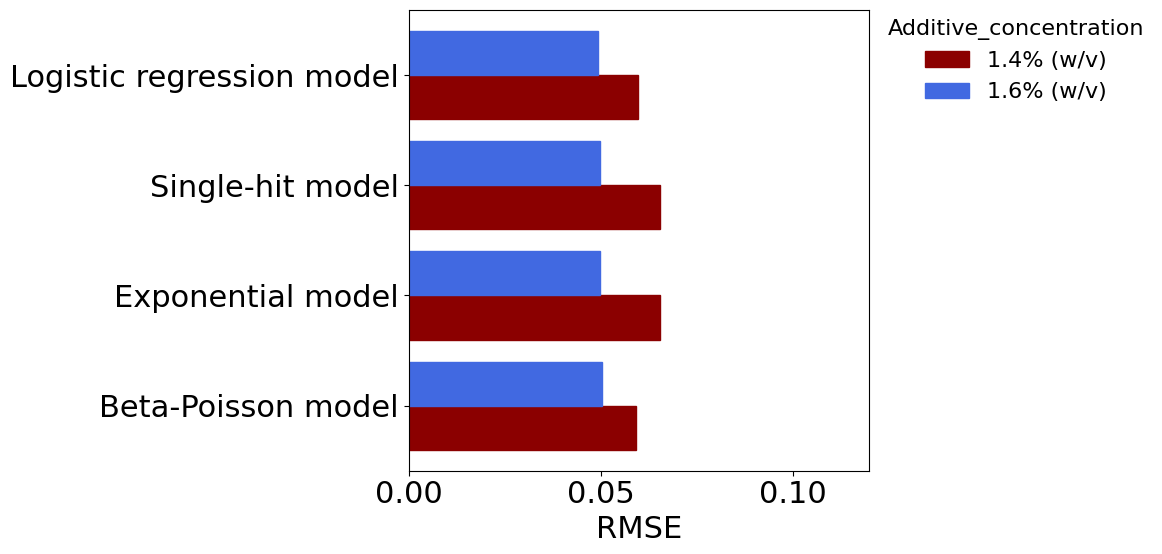

In [164]:
# RMSE version
plot_metric_by_model(
    df,
    bacterial_species="B.cereus", 
    additive_type="Glycine_[w/v_%]", 
    elapsed_time_days=3.0, 
    metric_col="RMSE",
    save=True,  
    save_dir="/workspace/results/figures",
    # filename_base を None にすると自動で名前生成
    filename_base="barhplot_model_RMSE_Bcereus_Glycine_14_16_day3_least_square_ver2025Dec12th"
    )

Saved: /workspace/results/figures/barhplot_model_AIC_Bcereus_Glycine_14_16_day3_least_square_ver2025Dec12th.tiff
Saved: /workspace/results/figures/barhplot_model_AIC_Bcereus_Glycine_14_16_day3_least_square_ver2025Dec12th_transparent.tiff


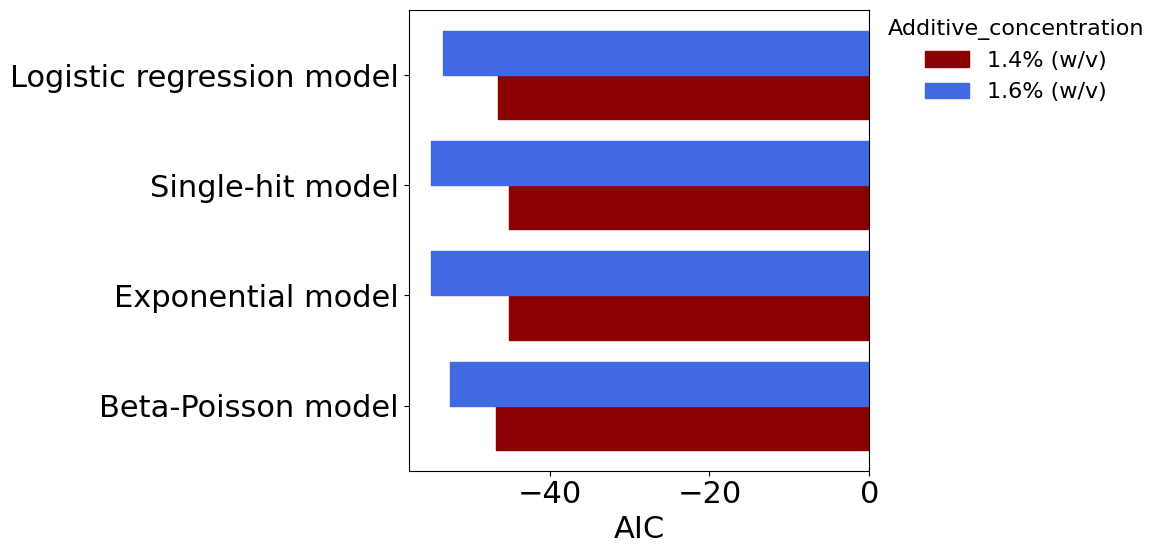

In [165]:
# AIC version
plot_metric_by_model(
    df,
    bacterial_species="B.cereus", 
    additive_type="Glycine_[w/v_%]", 
    elapsed_time_days=3.0, 
    metric_col="AIC",
    save=True,  
    save_dir="/workspace/results/figures",
    # filename_base を None にすると自動で名前生成
    filename_base="barhplot_model_AIC_Bcereus_Glycine_14_16_day3_least_square_ver2025Dec12th"
    )

### Day 7 


Saved: /workspace/results/figures/barhplot_model_RMSE_Bcereus_Glycine_14_16_day7_least_square_ver2025Dec12th.tiff
Saved: /workspace/results/figures/barhplot_model_RMSE_Bcereus_Glycine_14_16_day7_least_square_ver2025Dec12th_transparent.tiff


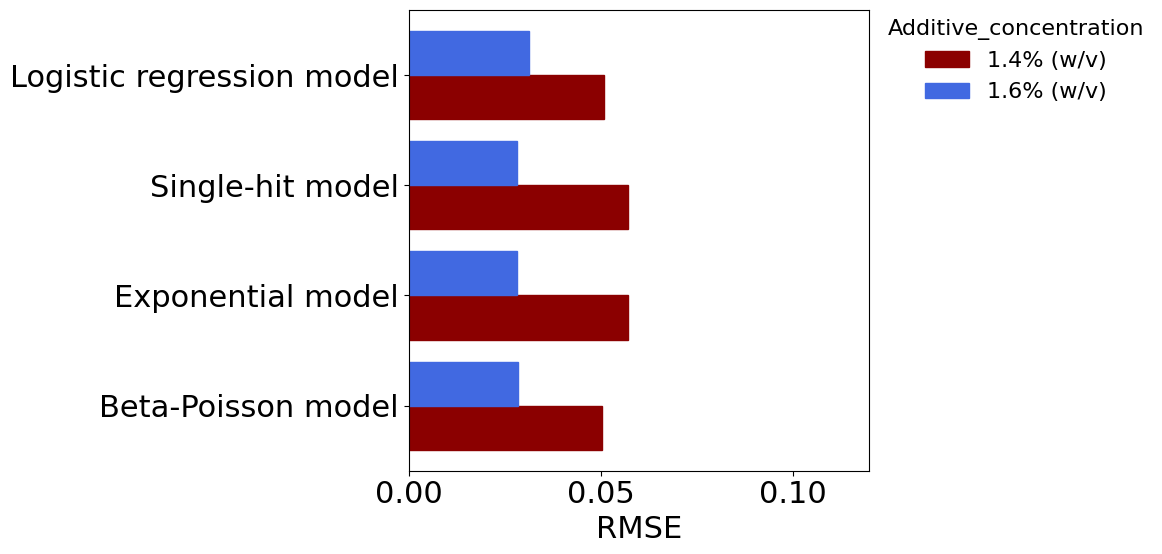

In [166]:
# RMSE version
plot_metric_by_model(
    df,
    bacterial_species="B.cereus", 
    additive_type="Glycine_[w/v_%]", 
    elapsed_time_days=7.0, 
    metric_col="RMSE",
    save=True,  
    save_dir="/workspace/results/figures",
    # filename_base を None にすると自動で名前生成
    filename_base="barhplot_model_RMSE_Bcereus_Glycine_14_16_day7_least_square_ver2025Dec12th"
    )

Saved: /workspace/results/figures/barhplot_model_AIC_Bcereus_Glycine_14_16_day7_least_square_ver2025Dec12th.tiff
Saved: /workspace/results/figures/barhplot_model_AIC_Bcereus_Glycine_14_16_day7_least_square_ver2025Dec12th_transparent.tiff


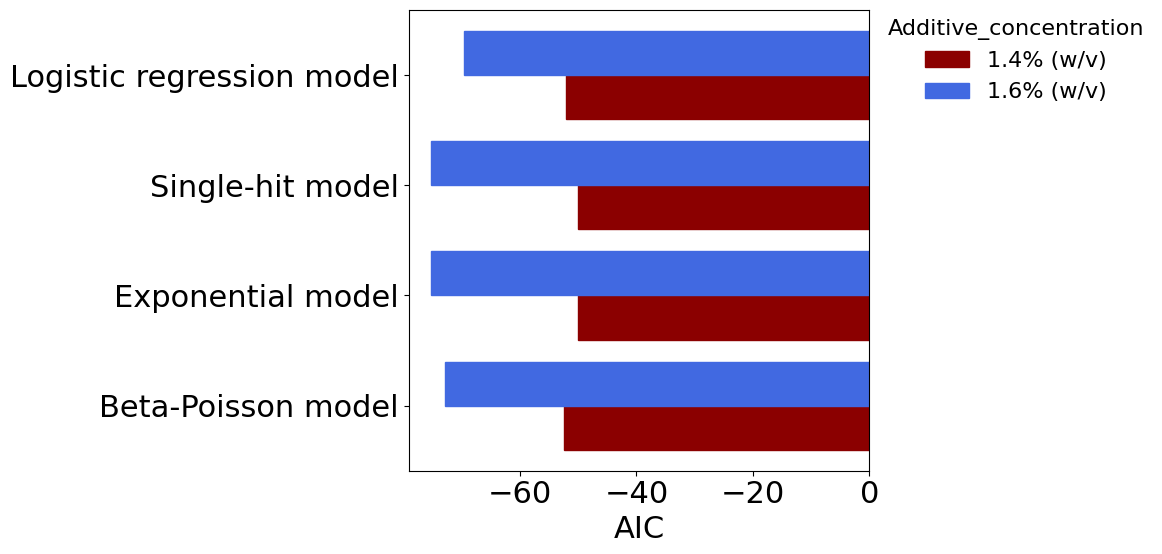

In [167]:
# AIC version
plot_metric_by_model(
    df,
    bacterial_species="B.cereus", 
    additive_type="Glycine_[w/v_%]", 
    elapsed_time_days=7.0, 
    metric_col="AIC",
    save=True,  
    save_dir="/workspace/results/figures",
    # filename_base を None にすると自動で名前生成
    filename_base="barhplot_model_AIC_Bcereus_Glycine_14_16_day7_least_square_ver2025Dec12th"
    )

### NaCl
- (lower: 7.0% (w/v), higher: 7.5% (w/v))


Saved: /workspace/results/figures/barhplot_model_RMSE_Bcereus_NaCl_70_75_day3_least_square_ver2025Dec12th.tiff
Saved: /workspace/results/figures/barhplot_model_RMSE_Bcereus_NaCl_70_75_day3_least_square_ver2025Dec12th_transparent.tiff


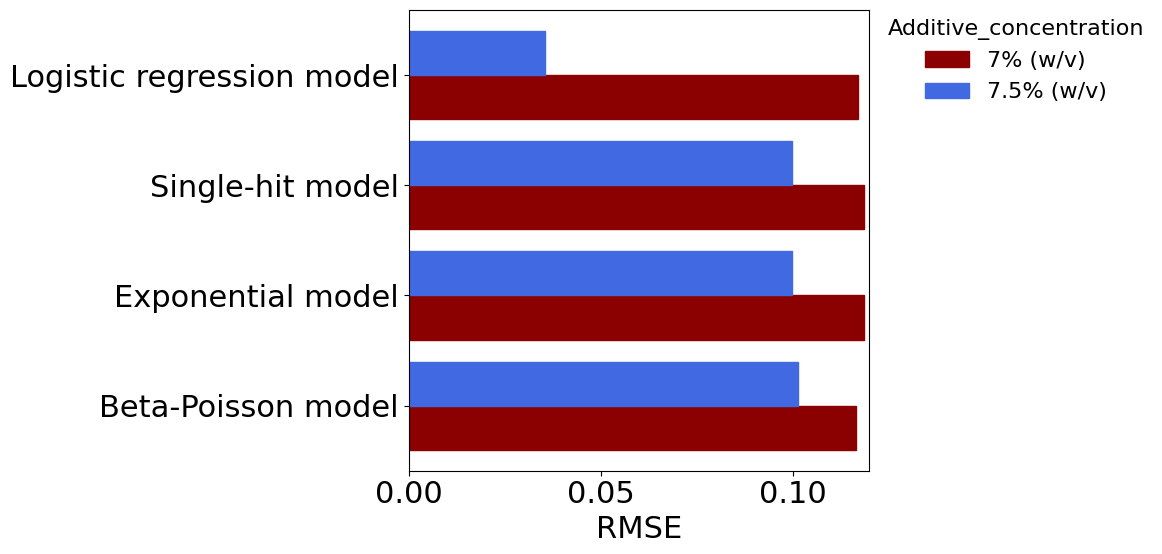

In [168]:
# RMSE version
plot_metric_by_model(
    df,
    bacterial_species="B.cereus", 
    additive_type="NaCl_[w/v_%]", 
    elapsed_time_days=3.0, 
    metric_col="RMSE",
    save=True,  
    save_dir="/workspace/results/figures",
    # filename_base を None にすると自動で名前生成
    filename_base="barhplot_model_RMSE_Bcereus_NaCl_70_75_day3_least_square_ver2025Dec12th"
    )

Saved: /workspace/results/figures/barhplot_model_AIC_Bcereus_NaCl_70_75_day3_least_square_ver2025Dec12th.tiff
Saved: /workspace/results/figures/barhplot_model_AIC_Bcereus_NaCl_70_75_day3_least_square_ver2025Dec12th_transparent.tiff


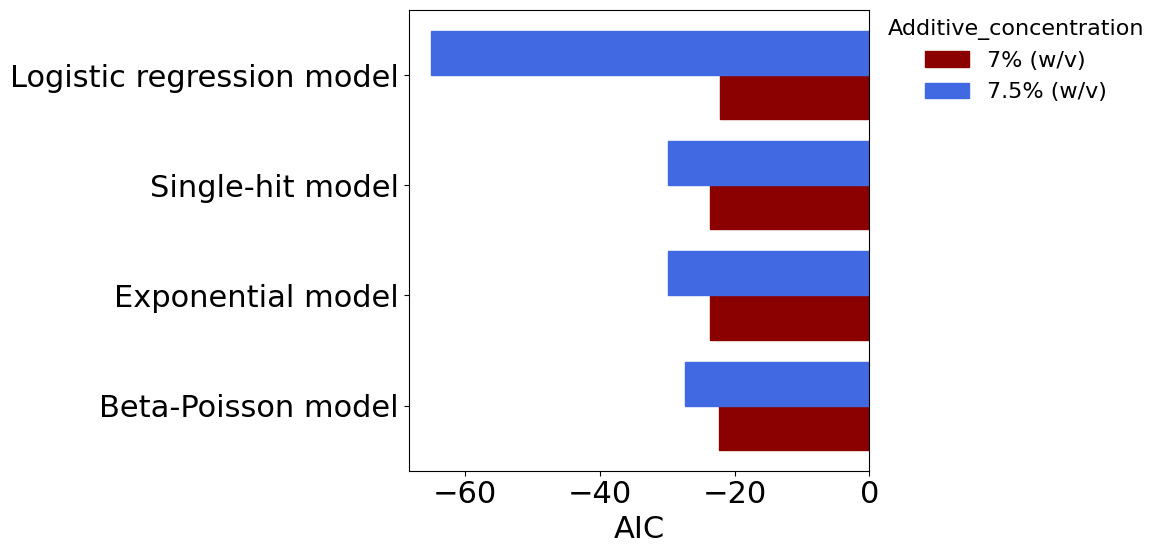

In [169]:
# AIC version
plot_metric_by_model(
    df,
    bacterial_species="B.cereus", 
    additive_type="NaCl_[w/v_%]", 
    elapsed_time_days=3.0, 
    metric_col="AIC",
    save=True,  
    save_dir="/workspace/results/figures",
    # filename_base を None にすると自動で名前生成
    filename_base="barhplot_model_AIC_Bcereus_NaCl_70_75_day3_least_square_ver2025Dec12th"
    )

### Day7

Saved: /workspace/results/figures/barhplot_model_RMSE_Bcereus_NaCl_70_75_day7_least_square_ver2025Dec12th.tiff
Saved: /workspace/results/figures/barhplot_model_RMSE_Bcereus_NaCl_70_75_day7_least_square_ver2025Dec12th_transparent.tiff


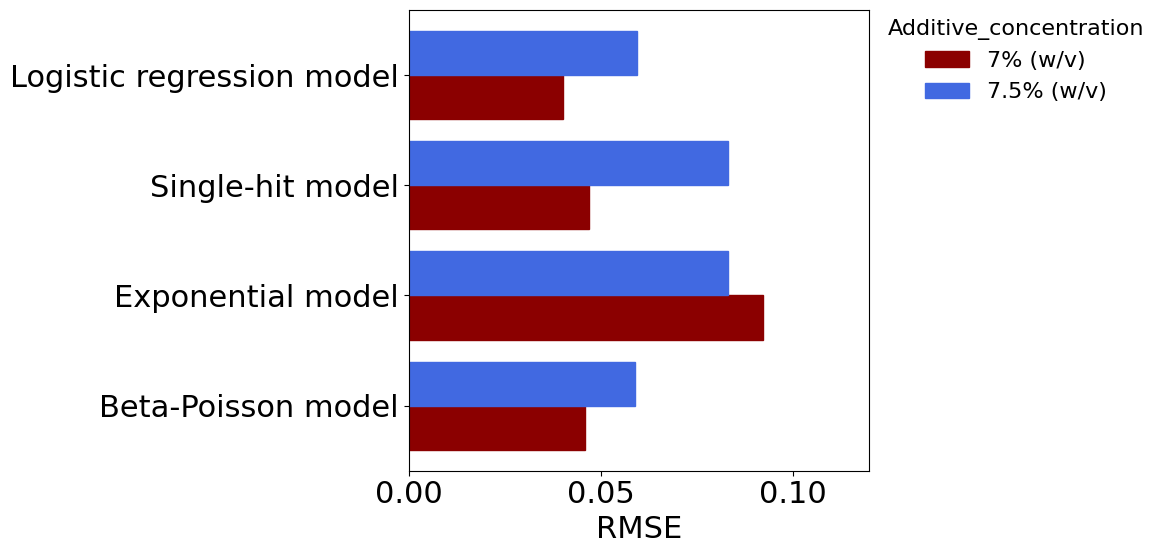

In [170]:
# RMSE version
plot_metric_by_model(
    df,
    bacterial_species="B.cereus", 
    additive_type="NaCl_[w/v_%]", 
    elapsed_time_days=7.0, 
    metric_col="RMSE",
    save=True,  
    save_dir="/workspace/results/figures",
    # filename_base を None にすると自動で名前生成
    filename_base="barhplot_model_RMSE_Bcereus_NaCl_70_75_day7_least_square_ver2025Dec12th"
    )

Saved: /workspace/results/figures/barhplot_model_AIC_Bcereus_NaCl_70_75_day7_least_square_ver2025Dec12th.tiff
Saved: /workspace/results/figures/barhplot_model_AIC_Bcereus_NaCl_70_75_day7_least_square_ver2025Dec12th_transparent.tiff


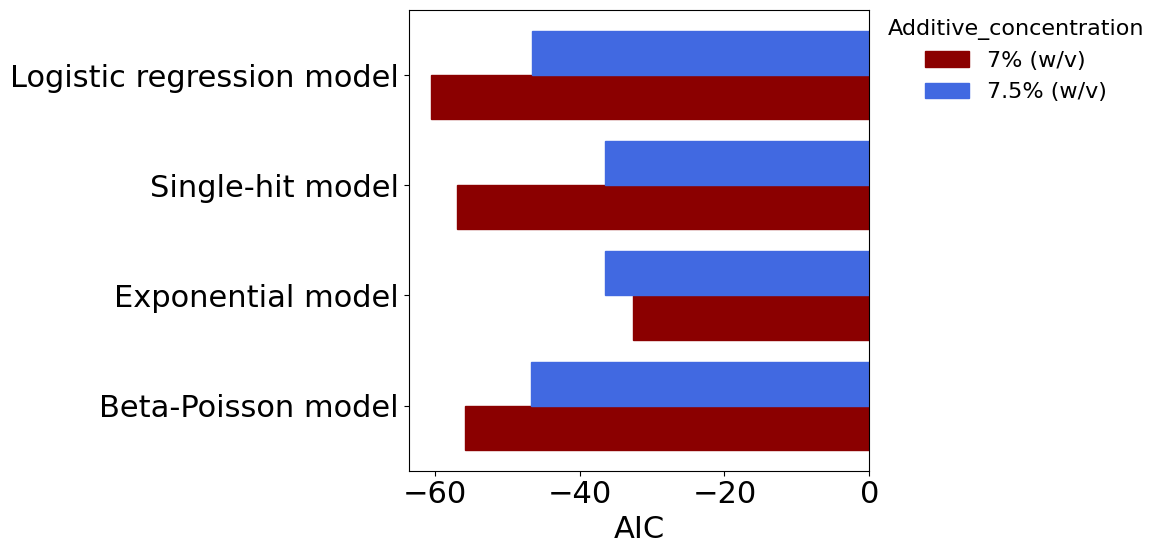

In [171]:
# AIC version
plot_metric_by_model(
    df,
    bacterial_species="B.cereus", 
    additive_type="NaCl_[w/v_%]", 
    elapsed_time_days=7.0, 
    metric_col="AIC",
    save=True,  
    save_dir="/workspace/results/figures",
    # filename_base を None にすると自動で名前生成
    filename_base="barhplot_model_AIC_Bcereus_NaCl_70_75_day7_least_square_ver2025Dec12th"
    )

# _E. coli_

### Glycine
- (lower: 1.7% (w/v), higher: 1.8% (w/v))


### Day3

Saved: /workspace/results/figures/barhplot_model_RMSE_Ecoli_Glycine_17_18_day3_least_square_ver2025Dec12th.tiff
Saved: /workspace/results/figures/barhplot_model_RMSE_Ecoli_Glycine_17_18_day3_least_square_ver2025Dec12th_transparent.tiff


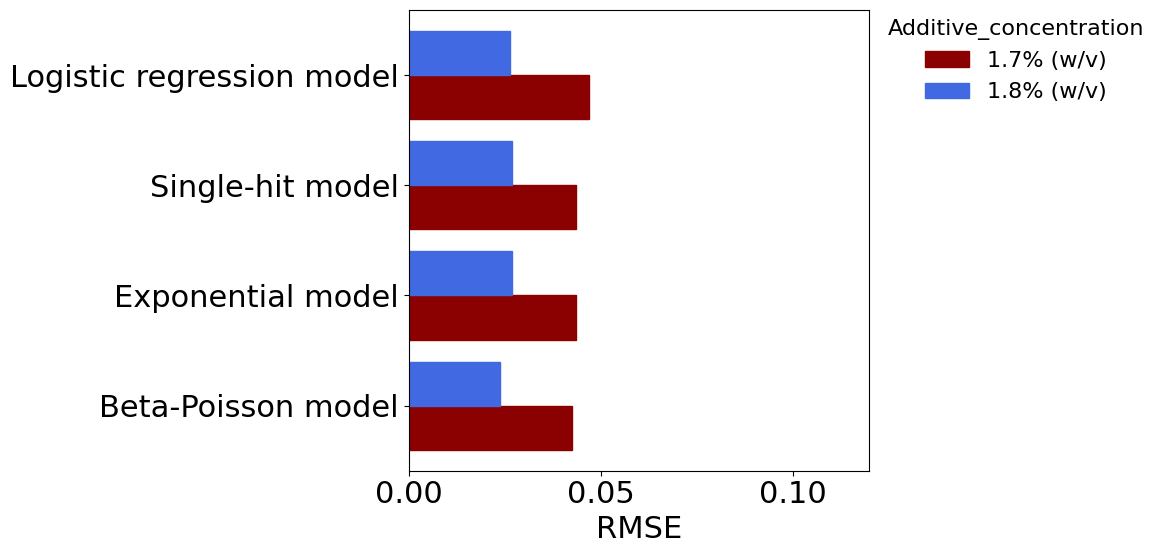

In [172]:
# RMSE version
plot_metric_by_model(
    df,
    bacterial_species="E.coli", 
    additive_type="Glycine_[w/v_%]", 
    elapsed_time_days=3.0, 
    metric_col="RMSE",
    save=True,  
    save_dir="/workspace/results/figures",
    # filename_base を None にすると自動で名前生成
    filename_base="barhplot_model_RMSE_Ecoli_Glycine_17_18_day3_least_square_ver2025Dec12th"
    )

Saved: /workspace/results/figures/barhplot_model_AIC_Ecoli_Glycine_17_18_day3_least_square_ver2025Dec12th.tiff
Saved: /workspace/results/figures/barhplot_model_AIC_Ecoli_Glycine_17_18_day3_least_square_ver2025Dec12th_transparent.tiff


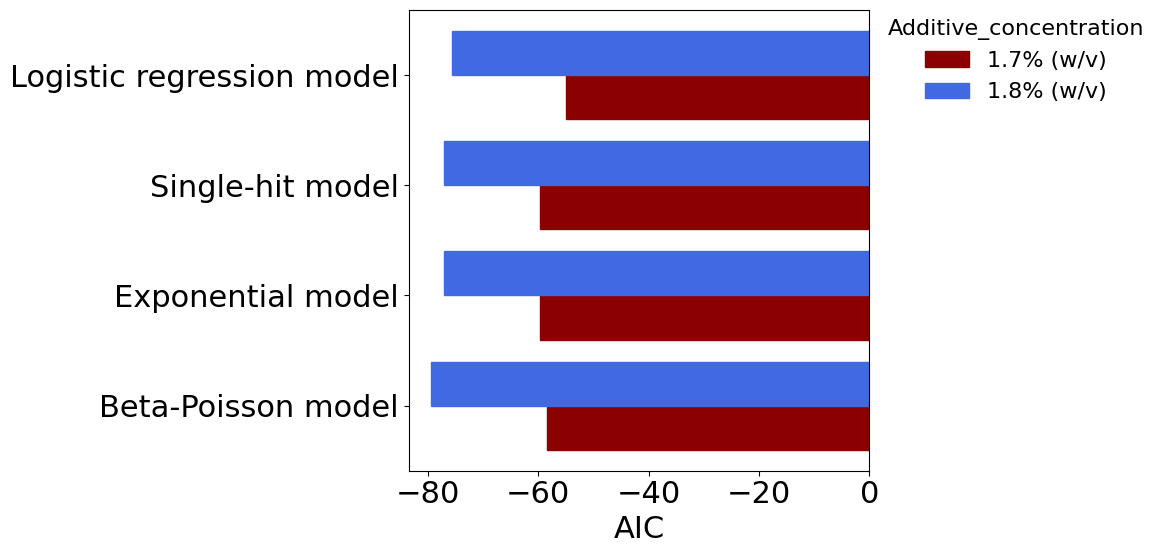

In [173]:
# AIC version
plot_metric_by_model(
    df,
    bacterial_species="E.coli", 
    additive_type="Glycine_[w/v_%]", 
    elapsed_time_days=3.0, 
    metric_col="AIC",
    save=True,  
    save_dir="/workspace/results/figures",
    # filename_base を None にすると自動で名前生成
    filename_base="barhplot_model_AIC_Ecoli_Glycine_17_18_day3_least_square_ver2025Dec12th"
    )

### Day7

Saved: /workspace/results/figures/barhplot_model_RMSE_Ecoli_Glycine_17_18_day7_least_square_ver2025Dec12th.tiff
Saved: /workspace/results/figures/barhplot_model_RMSE_Ecoli_Glycine_17_18_day7_least_square_ver2025Dec12th_transparent.tiff


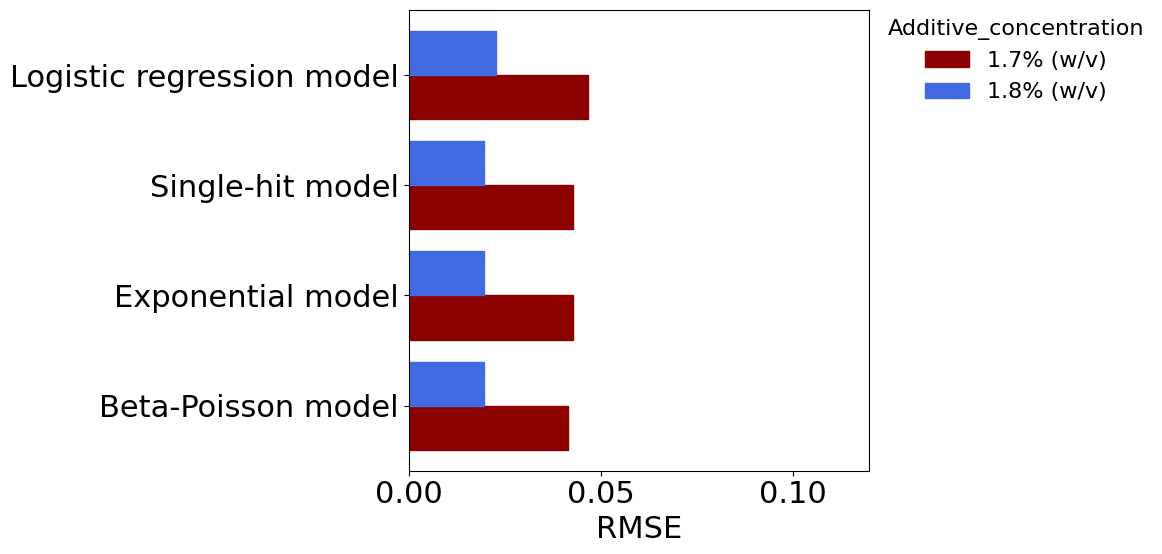

In [174]:
# RMSE version
plot_metric_by_model(
    df,
    bacterial_species="E.coli", 
    additive_type="Glycine_[w/v_%]", 
    elapsed_time_days=7.0, 
    metric_col="RMSE",
    save=True,  
    save_dir="/workspace/results/figures",
    # filename_base を None にすると自動で名前生成
    filename_base="barhplot_model_RMSE_Ecoli_Glycine_17_18_day7_least_square_ver2025Dec12th"
    )

Saved: /workspace/results/figures/barhplot_model_AIC_Ecoli_Glycine_17_18_day7_least_square_ver2025Dec12th.tiff
Saved: /workspace/results/figures/barhplot_model_AIC_Ecoli_Glycine_17_18_day7_least_square_ver2025Dec12th_transparent.tiff


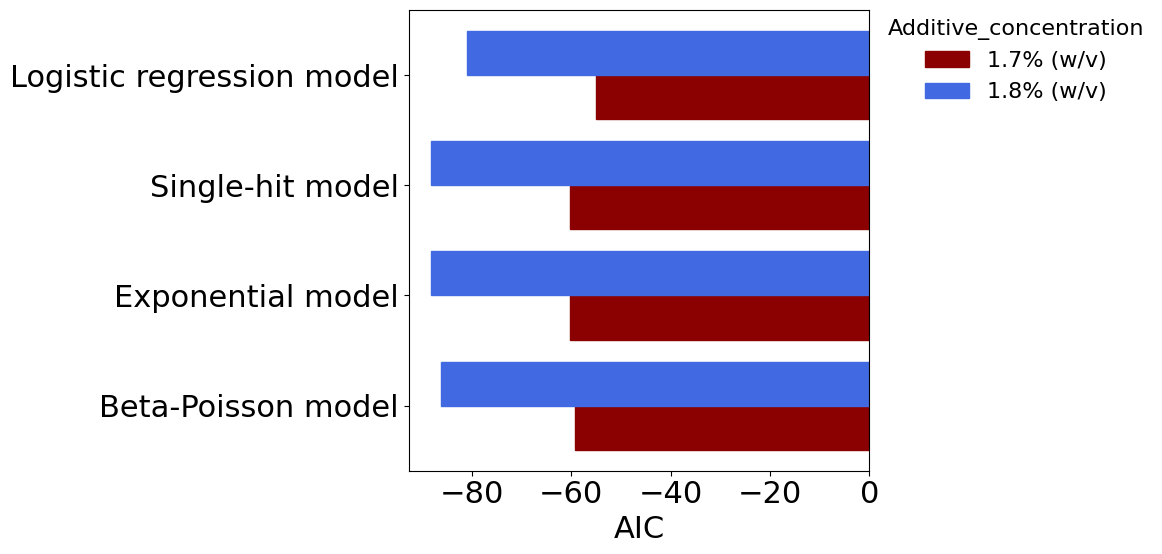

In [175]:
# AIC version
plot_metric_by_model(
    df,
    bacterial_species="E.coli", 
    additive_type="Glycine_[w/v_%]", 
    elapsed_time_days=7.0, 
    metric_col="AIC",
    save=True,  
    save_dir="/workspace/results/figures",
    # filename_base を None にすると自動で名前生成
    filename_base="barhplot_model_AIC_Ecoli_Glycine_17_18_day7_least_square_ver2025Dec12th"
    )

### NaCl
- (lower: 6.5% (w/v), higher: 7.0% (w/v))


Saved: /workspace/results/figures/barhplot_model_RMSE_Ecoli_NaCl_65_70_day3_least_square_ver2025Dec12th.tiff
Saved: /workspace/results/figures/barhplot_model_RMSE_Ecoli_NaCl_65_70_day3_least_square_ver2025Dec12th_transparent.tiff


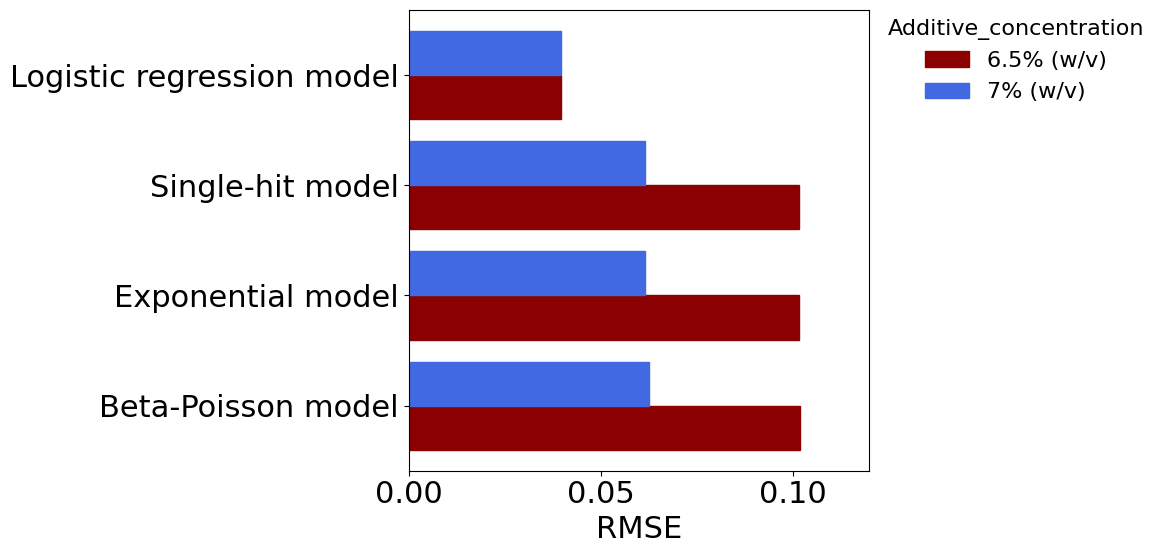

In [176]:
# RMSE version
plot_metric_by_model(
    df,
    bacterial_species="E.coli", 
    additive_type="NaCl_[w/v_%]", 
    elapsed_time_days=3.0, 
    metric_col="RMSE",
    save=True,  
    save_dir="/workspace/results/figures",
    # filename_base を None にすると自動で名前生成
    filename_base="barhplot_model_RMSE_Ecoli_NaCl_65_70_day3_least_square_ver2025Dec12th"
    )

Saved: /workspace/results/figures/barhplot_model_AIC_Ecoli_NaCl_65_70_day3_least_square_ver2025Dec12th.tiff
Saved: /workspace/results/figures/barhplot_model_AIC_Ecoli_NaCl_65_70_day3_least_square_ver2025Dec12th_transparent.tiff


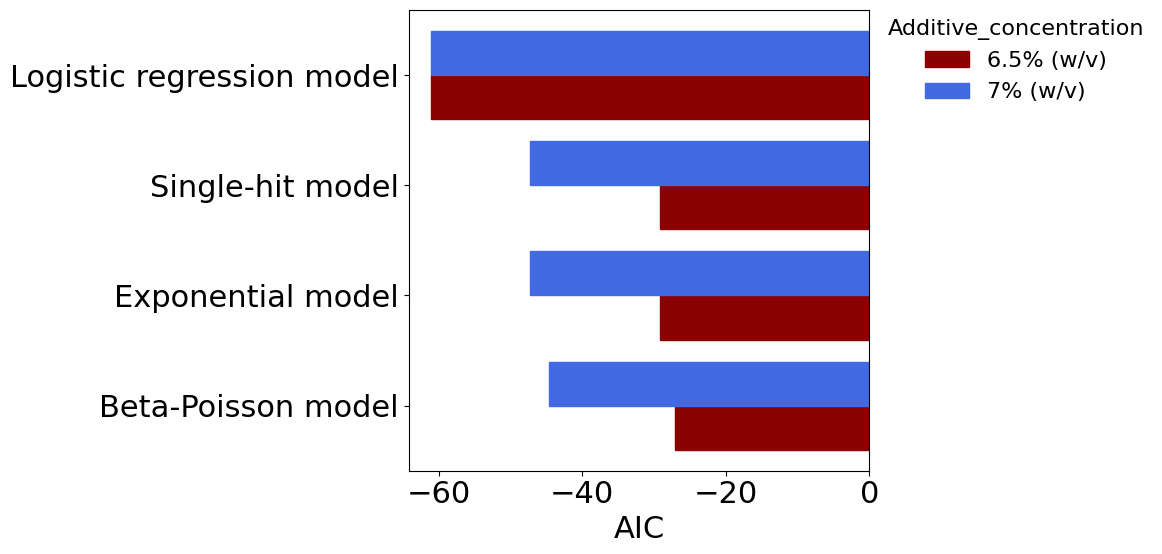

In [177]:
# AIC version
plot_metric_by_model(
    df,
    bacterial_species="E.coli", 
    additive_type="NaCl_[w/v_%]", 
    elapsed_time_days=3.0, 
    metric_col="AIC",
    save=True,  
    save_dir="/workspace/results/figures",
    # filename_base を None にすると自動で名前生成
    filename_base="barhplot_model_AIC_Ecoli_NaCl_65_70_day3_least_square_ver2025Dec12th"
    )

### Day7

Saved: /workspace/results/figures/barhplot_model_RMSE_Ecoli_NaCl_65_70_day7_least_square_ver2025Dec12th.tiff
Saved: /workspace/results/figures/barhplot_model_RMSE_Ecoli_NaCl_65_70_day7_least_square_ver2025Dec12th_transparent.tiff


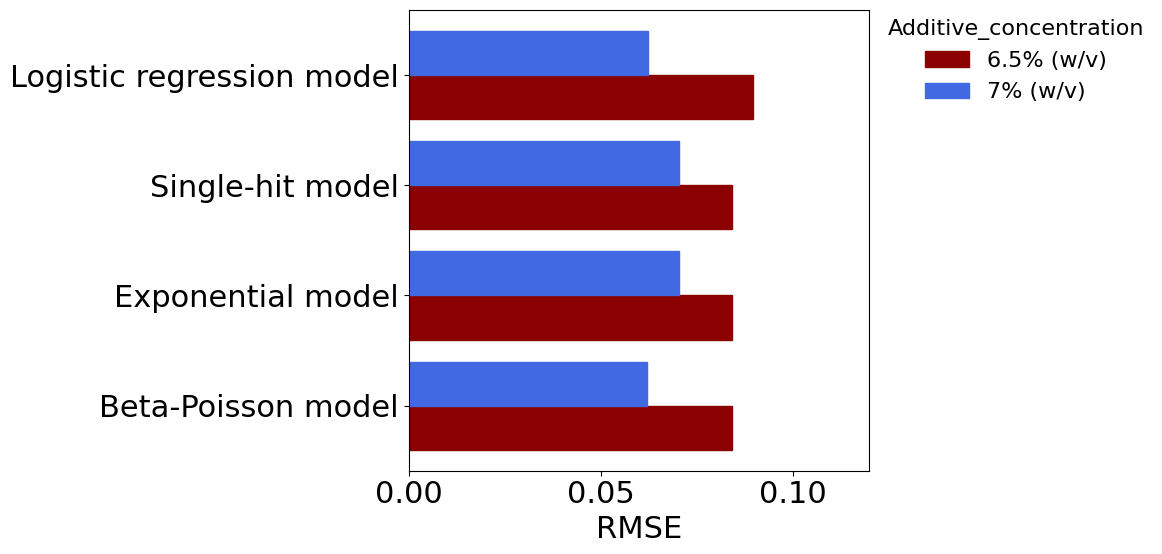

In [178]:
# RMSE version
plot_metric_by_model(
    df,
    bacterial_species="E.coli", 
    additive_type="NaCl_[w/v_%]", 
    elapsed_time_days=7.0, 
    metric_col="RMSE",
    save=True,  
    save_dir="/workspace/results/figures",
    # filename_base を None にすると自動で名前生成
    filename_base="barhplot_model_RMSE_Ecoli_NaCl_65_70_day7_least_square_ver2025Dec12th"
    )

Saved: /workspace/results/figures/barhplot_model_AIC_Ecoli_NaCl_65_70_day7_least_square_ver2025Dec12th.tiff
Saved: /workspace/results/figures/barhplot_model_AIC_Ecoli_NaCl_65_70_day7_least_square_ver2025Dec12th_transparent.tiff


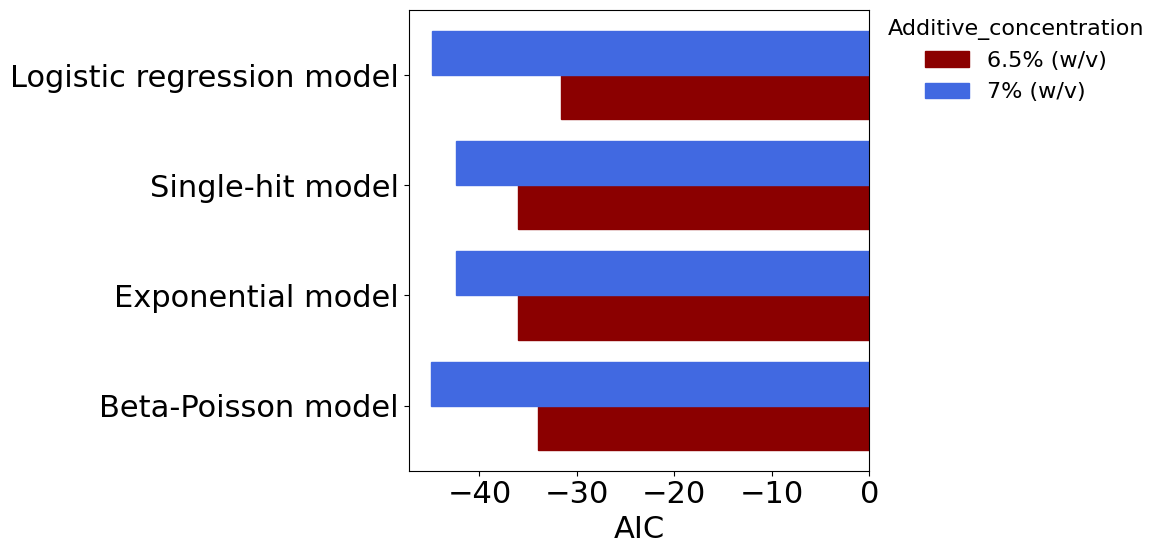

In [179]:
# AIC version
plot_metric_by_model(
    df,
    bacterial_species="E.coli", 
    additive_type="NaCl_[w/v_%]", 
    elapsed_time_days=7.0, 
    metric_col="AIC",
    save=True,  
    save_dir="/workspace/results/figures",
    # filename_base を None にすると自動で名前生成
    filename_base="barhplot_model_AIC_Ecoli_NaCl_65_70_day7_least_square_ver2025Dec12th"
    )